## Importação das bibliotecas


In [5]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split #divisao dos dados treino/teste
from sklearn.preprocessing import StandardScaler #padronizar dados numericos
from sklearn.neighbors import KNeighborsClassifier  #Vizinhos próximos
from sklearn.tree import DecisionTreeClassifier #arvore de decisao
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix #acuracia, relatorio de classificacao, matriz de confusao
    
#Configurações dos gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)




## Carregamento dos dados (occupancy_completo.csv)

In [6]:
caminho_csv = os.path.join('..','data', 'occupancy_completo.csv')

if not os.path.exists(caminho_csv):
    raise FileNotFoundError(f'Arquivo não encontrado em: {caminho_csv}')

df = pd.read_csv(caminho_csv)
print('Arquivos carregados com sucesso')
df.head()

Arquivos carregados com sucesso


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
1,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
2,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
3,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
4,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


## Fase 1: Análise exploratória (EDA)

In [7]:
def exploracao_inicial(df):
    print('Iniciando Análise Exploratória...')
    print(f'\nNúmero de linhas: {df.shape[0]} | Número de colunas: {df.shape[1]}')
    print('\nTipos de dados:')
    print(df.dtypes)
    print('\nInformações sobre os dados:')
    print(df.info())
    print('\nResumo estatistico:')
    print(df.describe())

exploracao_inicial(df)
    

Iniciando Análise Exploratória...

Número de linhas: 20560 | Número de colunas: 7

Tipos de dados:
date                 str
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

Informações sobre os dados:
<class 'pandas.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  str    
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          20560 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 1.1 MB
None

Resumo estatistico:
        Temperature      Humidity         Light           CO2  HumidityRatio  \
count  20560.000000  20560

### Coluna date

Vamos excluir a coluna date pois não é útil para o modelo.




In [8]:
dados = df.copy() 

dados = df.drop(columns=['date']) 
dados.head()



,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.18,27.2720,426.0,721.25,0.004793,1
1,23.15,27.2675,429.5,714.00,0.004783,1
2,23.15,27.2450,426.0,713.50,0.004779,1
3,23.15,27.2000,426.0,708.25,0.004772,1
4,23.10,27.2000,426.0,704.50,0.004757,1


### Graficos de distribuicao


#### Histograma de distribuiçao das variaveis preditoras.

OBS:
- As variáveis preditoras sao: Temperature, Humidity, Light, CO2, HumidityRatio
- A variável alvo é: Occupancy

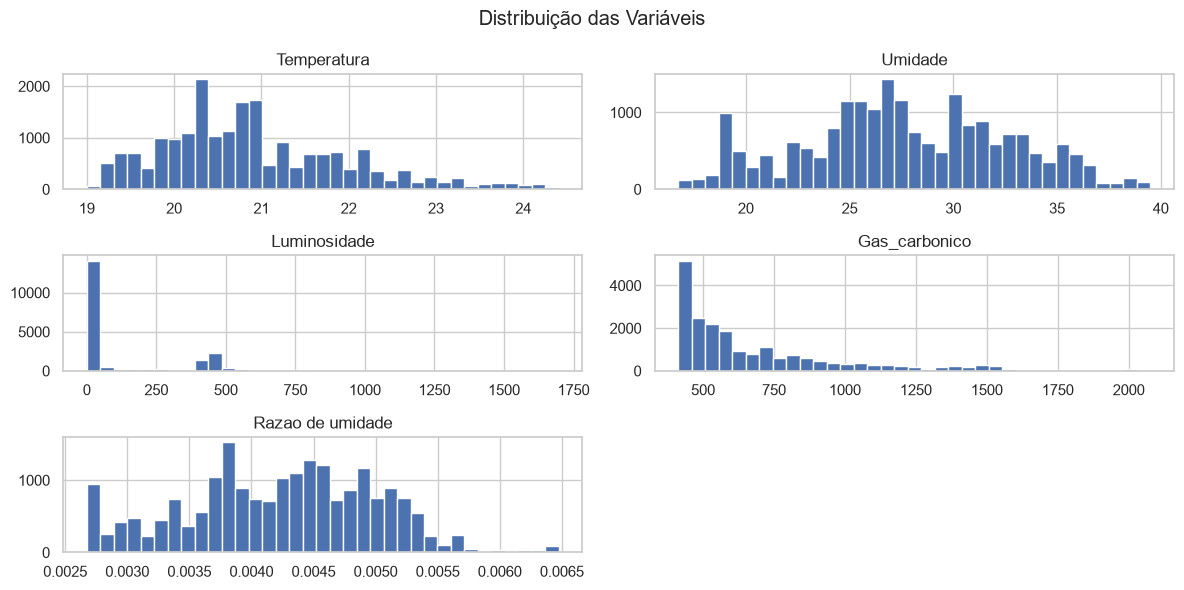

In [9]:
preditoras_traducao = {
    'Temperature': 'Temperatura',
    'Humidity': 'Umidade',
    'Light': 'Luminosidade',
    'CO2': 'Gas_carbonico',
    'HumidityRatio': 'Razao de umidade'
}

colunas_preditoras = ['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio']

dados[colunas_preditoras].rename(columns=preditoras_traducao).hist(bins=35)
plt.suptitle("Distribuição das Variáveis")
plt.tight_layout()
plt.show()



#### Gráfico de barras para verificar a proporção das classes da variável alvo Occupancy

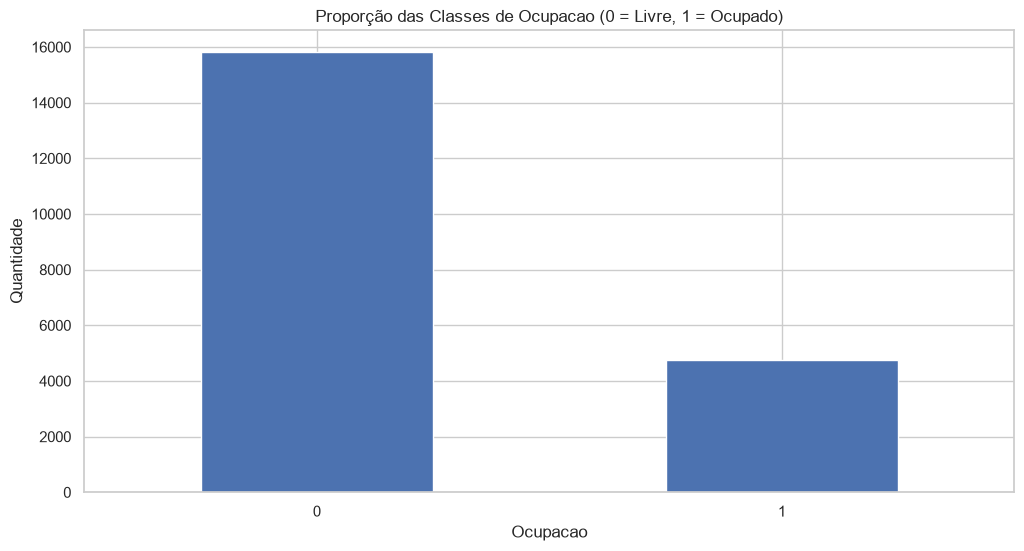

Occupancy
0    15810
1     4750
Name: count, dtype: int64

In [10]:
alvo_traducao = {'Occupancy': 'Ocupacao'}

coluna_alvo = 'Occupancy'

dados[coluna_alvo].value_counts().sort_index().plot(kind="bar")
plt.title(f"Proporção das Classes de {alvo_traducao[coluna_alvo]} (0 = Livre, 1 = Ocupado)")
plt.xlabel(alvo_traducao[coluna_alvo])
plt.ylabel("Quantidade")
plt.xticks(rotation=0)
plt.show()

dados[coluna_alvo].value_counts()


In [11]:
dados[coluna_alvo].value_counts(normalize=True)


Occupancy
0    0.768969
1    0.231031
Name: proportion, dtype: float64

#### Mapa de calor com a correlação de Pearson entre as variáveis

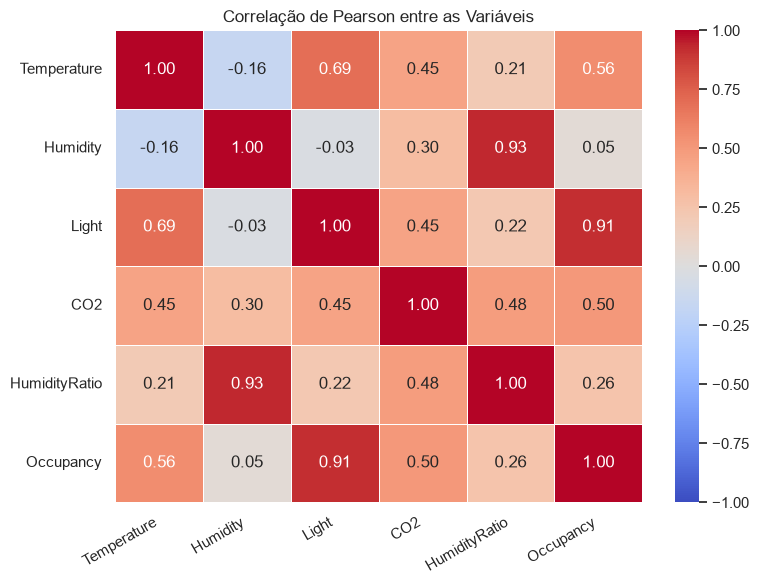

In [12]:
colunas_traducao = {
    'Temperature': 'Temperatura',
    'Humidity': 'Umidade',
    'Light': 'Luminosidade',
    'CO2': 'Gas_carbonico',
    'HumidityRatio': 'Razao de umidade',
    'Occupancy': 'Ocupacao'
}

plt.figure(figsize=(8, 6))
sns.heatmap(
    dados.corr(method="pearson"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
)
plt.title("Correlação de Pearson entre as Variáveis")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Análise dos resultados

- O grafico das categorias da Ocupacao deixa claro que o grande volume (76,89%) dos dados foram registrados em ambientes livres.
- Correlacao com Ocupacao: a luminoside é a variável com a maior correlaçao (91%) com a ocupacao. A segunda variável é Temperatura (56%), seguida por CO2 (50%), Razao da umidade com 26% e a umidade tem a menor correlacao, apenas 5%.
- Histograma: A grande maioria dos dados tem luminosidade Zero (luzes apagadas).


### Estratégia de modelagem

A árvore de decisao é a melhor escolha para esse conjunto de dados, as vantagens são:
- funciona como um fluxograma de perguntas (Regras Condicionais).
- Dispensa normalização (igualar escala)
- O modelo nao se confunde com colunas quase repetidas, por exemplo umidade e razao de umidade (correlacao de 93%)

## FASE 2: Limpeza e tratamento de dados (DATAPREP)

### Linhas duplicadas

In [13]:
duplicadas = dados.duplicated().sum()
print(f'total de linhas duplicadas: {duplicadas}')
print(f'total de linhas antes da exclusao: {dados.shape[0]}')

dados = dados.drop_duplicates()
print(f'total de linhas após a exlusao: {dados.shape[0]}')


total de linhas duplicadas: 1441
total de linhas antes da exclusao: 20560
total de linhas após a exlusao: 19119


### Verificacao de ausentes

In [14]:
nulos = dados.isna().sum()
print(f'total de valores nulos: {nulos}')

total de valores nulos: Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


Não existem colunas com dados nulos nem linhas duplicadas, possivelmente a base de dados foi já tratada anteriormente.
Caso houvesse dados nulos, optaria por preenche-los com a mediana pois é robusta a valores extremos e proteger as colunas contra distorçoes.

### Boxplot para identificar outliers

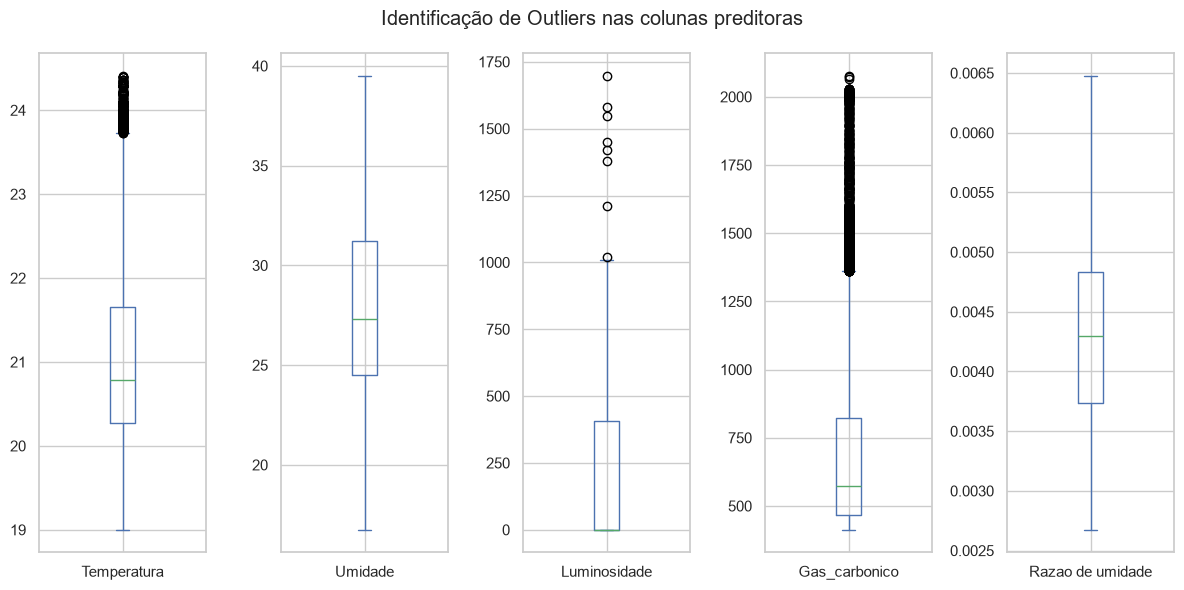

In [19]:
dados[list(preditoras_traducao.keys())].rename(columns=preditoras_traducao).plot(
    kind='box',
    subplots=True,
    layout=(1, 5),
    title='Identificação de Outliers nas colunas preditoras'
)
plt.tight_layout()
plt.show()

- Gas carbonico tem a maior concentracao de outliers, existem muitos pontos acima do limite superior (aproximadamente 1300), com valor maximo proximo a 2000.
- Temperatura tem uma leve assimetria para cima, a grande maioria das mediçoes esta na dentro da faixa de 22 a 24 graus.
- Umidade e Razao da umidade nao tem outliers, os dados sem simétricos, confirmando que essas variaveis tem pouca relaácao com a ocupaçao da sala.

## FASE 3: Feature Engineering

Criaçao de uma nova coluna matemática com a combinacao de colunas existentes    

In [21]:
dados['indice_calor_umidade'] = dados['Temperature'] * dados['Humidity']

dados['razao_co2_lux'] = dados['CO2'] /(dados['Light'] + 1)

dados.head()

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy,indice_calor_umidade,razao_co2_lux
0,23.18,27.2720,426.0,721.25,0.004793,1,632.164960,1.689110
1,23.15,27.2675,429.5,714.00,0.004783,1,631.242625,1.658537
2,23.15,27.2450,426.0,713.50,0.004779,1,630.721750,1.670960
3,23.15,27.2000,426.0,708.25,0.004772,1,629.680000,1.658665
4,23.10,27.2000,426.0,704.50,0.004757,1,628.320000,1.649883


In [25]:
print('Estatisticas da coluna indice_calor_umidade:')

print(dados['indice_calor_umidade'].describe())

Estatisticas da coluna indice_calor_umidade:
count    19119.000000
mean       578.982575
std        101.988916
min        371.854100
25%        515.384100
50%        586.509000
75%        658.053000
max        865.413900
Name: indice_calor_umidade, dtype: float64


In [27]:
print('Estatisticas da coluna razao_CO2_lux:')

print(dados['razao_co2_lux'].describe())

Estatisticas da coluna razao_CO2_lux:
count    19119.000000
mean       371.428659
std        366.581667
min          0.294270
25%          2.814018
50%        441.666667
75%        548.000000
max       2076.500000
Name: razao_co2_lux, dtype: float64


## FASE 4: Divisão e balanceamento dos dados



In [29]:
X = dados[colunas_preditoras]
y = dados[coluna_alvo]

# divisao de treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(
    f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas\n"
)
print("Proporção no Treino (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))
print("\nProporção no Teste (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Treino: 15295 linhas | Teste: 3824 linhas

Proporção no Treino (%):
Occupancy
0    75.17
1    24.83
Name: proportion, dtype: float64

Proporção no Teste (%):
Occupancy
0    75.18
1    24.82
Name: proportion, dtype: float64


### Importancia da divisao antes da transformacao (revenção de Data Leakage)

O vazamento de dados ocorre quando informacao da base de teste influenciam o treinamento do modelo antes da validacao final.
Caso usasse normalizacao, padronizaa 



